            temperature
date                   
2021-01-01         21.1
2021-01-02         20.3
2021-01-03         19.7
2021-01-04         20.3
2021-01-05         22.4
Missing values: 0


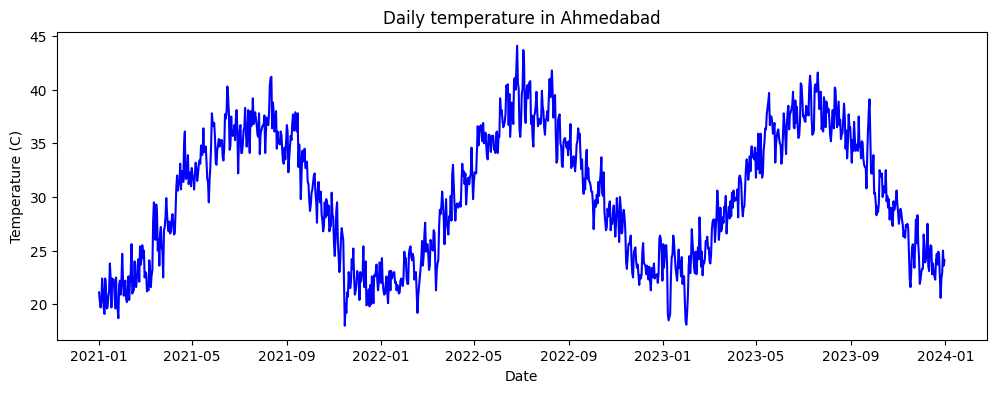

In [1]:
#Task 1: Plot daily temperature of Ahmedabad
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

df = pd.read_csv("ahmedabad_temperature.csv", parse_dates=["date"], index_col="date")
df = df.asfreq("D")
print(df.head())
print("Missing values:", df["temperature"].isnull().sum())

plt.figure(figsize=(12, 4))
plt.plot(df.index, df["temperature"], color="blue")
plt.xlabel("Date")
plt.ylabel("Temperature (C)")
plt.title("Daily temperature in Ahmedabad")
plt.show()

# The temperature goes up and down in the same way every year (hot summer, cooler winter), so there is a clear yearly seasonality.
# There is also a very slight upward trend over the three years.

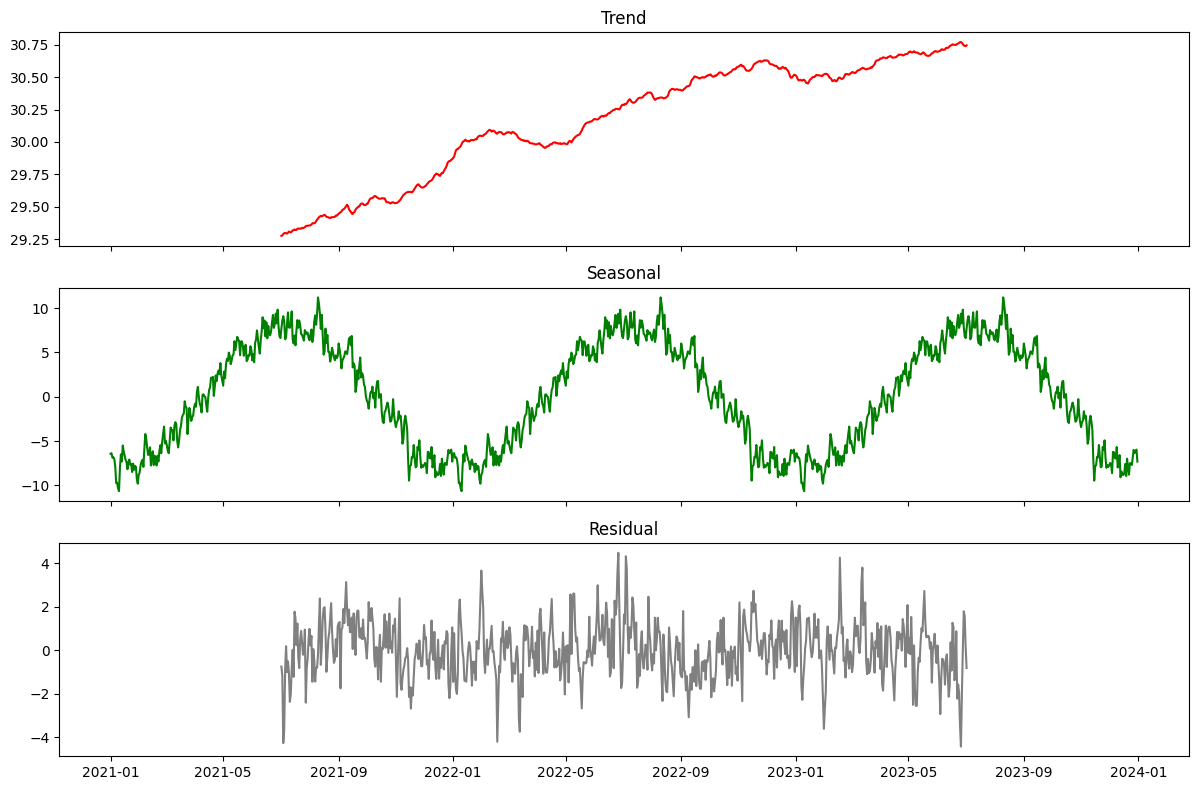

In [2]:
#Task 2: Decompose into trend, seasonal and residual
from statsmodels.tsa.seasonal import seasonal_decompose

dec = seasonal_decompose(df["temperature"], model="additive", period=365)

fig, ax = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
ax[0].plot(dec.trend, color="red")
ax[0].set_title("Trend")
ax[1].plot(dec.seasonal, color="green")
ax[1].set_title("Seasonal")
ax[2].plot(dec.resid, color="gray")
ax[2].set_title("Residual")
plt.tight_layout()
plt.show()

In [3]:
#Task 3: ADF test for stationarity
from statsmodels.tsa.stattools import adfuller

res = adfuller(df["temperature"])
print("ADF test statistic:", round(res[0], 4))
print("p-value:", round(res[1], 4))

if res[1] < 0.05:
    print("p-value is less than 0.05, so the series is likely stationary.")
else:
    print("p-value is not less than 0.05, so the series is likely not stationary.")

# The p-value is much higher than 0.05, so the series is not stationary (it has a trend and a yearly seasonal pattern).
# So we need differencing, which means d = 1 in ARIMA.

ADF test statistic: -1.6358
p-value: 0.4645
p-value is not less than 0.05, so the series is likely not stationary.


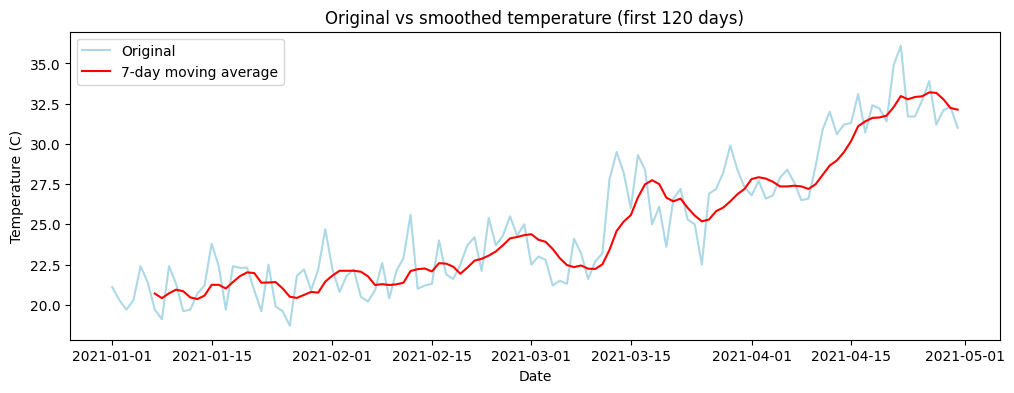

In [4]:
#Task 4: Moving average smoothing with window size 7
df["smooth7"] = df["temperature"].rolling(window=7).mean()

# only the first 120 days are plotted so that the difference is easy to see
part = df.iloc[:120]
plt.figure(figsize=(12, 4))
plt.plot(part.index, part["temperature"], color="lightblue", label="Original")
plt.plot(part.index, part["smooth7"], color="red", label="7-day moving average")
plt.xlabel("Date")
plt.ylabel("Temperature (C)")
plt.title("Original vs smoothed temperature (first 120 days)")
plt.legend()
plt.show()

ADF p-value after differencing once: 5.746977115063728e-17


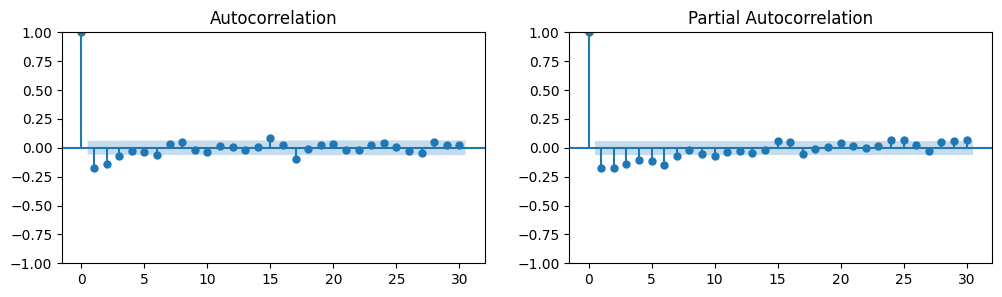

Order (1, 1, 1) -> AIC: 4033.9
Order (2, 1, 1) -> AIC: 4032.2


Order (2, 1, 2) -> AIC: 3984.7



Forecast for the next 7 days:
2024-01-01    23.6
2024-01-02    23.4
2024-01-03    23.2
2024-01-04    23.1
2024-01-05    23.0
2024-01-06    23.0
2024-01-07    22.9
Freq: D, Name: predicted_mean, dtype: float64


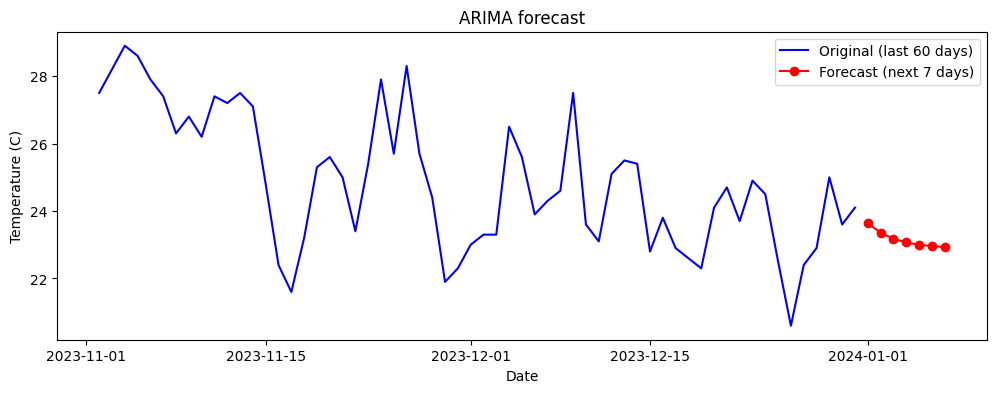

In [5]:
#Task 5: ARIMA model and 7 day forecast
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
warnings.filterwarnings("ignore")   # statsmodels turns warnings back on when it is imported, so switch them off again here

# the ADF test said the series is not stationary, so take d = 1 (first difference) and check it again
diff1 = df["temperature"].diff().dropna()
print("ADF p-value after differencing once:", adfuller(diff1)[1])

# ACF and PACF plots of the differenced series to help choose p and q
fig, ax = plt.subplots(1, 2, figsize=(12, 3))
plot_acf(diff1, lags=30, ax=ax[0])
plot_pacf(diff1, lags=30, ax=ax[1])
plt.show()

# Both plots show a few small spikes in the first lags, so small p and q are enough. A few small orders are compared with AIC (lower is better)
for o in [(1, 1, 1), (2, 1, 1), (2, 1, 2)]:
    print("Order", o, "-> AIC:", round(ARIMA(df["temperature"], order=o).fit().aic, 1))

order = (2, 1, 2)    # d = 1 from the ADF test, p = 2 and q = 2 from the plots and the lowest AIC
model = ARIMA(df["temperature"], order=order)
fit = model.fit()

fc = fit.forecast(steps=7)
print("\nForecast for the next 7 days:")
print(fc.round(1))

# ARIMA here has no seasonal part, so the forecast changes only a little from day to day.

last = df["temperature"].iloc[-60:]
plt.figure(figsize=(12, 4))
plt.plot(last.index, last, color="blue", label="Original (last 60 days)")
plt.plot(fc.index, fc, color="red", marker="o", label="Forecast (next 7 days)")
plt.xlabel("Date")
plt.ylabel("Temperature (C)")
plt.title("ARIMA forecast")
plt.legend()
plt.show()